# 03 Monitoring the training and fighting overfitting

**Goal of this notebook.** In notebook 02 the MLP learned its training images by heart (99.7 %)
but reached only about 40 % on new paintings. Here we:

1. **look inside the network during training**: the gradient of each layer, the "dead" neurons and
   the size of the weights, not only the loss;
2. **choose the learning rate** with a sweep (many short trainings);
3. **test the tools of session 6** against overfitting (weight decay, dropout, batch normalisation,
   data augmentation, early stopping), one by one and all together;
4. **look at the mistakes** of our best MLP.

We use 32 x 32 pixel images (notebook 02 showed that more pixels do not help an MLP). Every setting is
trained with 3 seeds, because one run on 219 validation images is a noisy measure.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from museum_guide.config import FAST_RUN, set_seed
from museum_guide.data import class_names, load_split_tensors
from museum_guide.diagnostics import chance_loss, lr_sweep, make_monitor, weight_norm
from museum_guide.evaluation import confusion_matrix, most_confused, per_class_report, save_results
from museum_guide.models import init_weights, make_mlp
from museum_guide.plots import PALETTE, plot_compare, plot_confusion, plot_history, plot_layers, save_figure
from museum_guide.recipes import MLP_BASELINE, MLP_REGULARISED, train_mlp
from museum_guide.training import evaluate, make_loaders, predict, summary

set_seed()
SEEDS = [0] if FAST_RUN else [0, 1, 2]
SWEEP_EPOCHS = 5 if FAST_RUN else 15
loss_fn = nn.CrossEntropyLoss()


def recipe(base, **changes):
    """A copy of a recipe with some settings changed (and short trainings when FAST_RUN=1)."""
    cfg = {k: v for k, v in base.items() if k != "size"}
    cfg.update(changes)
    if FAST_RUN:
        cfg["epochs"] = min(cfg.get("epochs", 40), 8)
    return cfg


data, meta = load_split_tensors(32)
X_train, y_train = data["train"]
X_val, y_val = data["val"]
classes = class_names(meta)
loaders = make_loaders(X_train, y_train, X_val, y_val, batch_size=64)
monitor_X, monitor_y = X_train[:256], y_train[:256]  # a fixed batch to measure gradients and activations
print("train", tuple(X_train.shape), "| validation", tuple(X_val.shape), "| seeds", SEEDS)

train (1061, 3, 32, 32) | validation (219, 3, 32, 32) | seeds [0, 1, 2]


## 1. Looking inside the baseline during training

**What we do.** We train the baseline of notebook 02 again (Adam, learning rate 0.001, 40 epochs) and
after each epoch we measure, on a fixed batch of 256 training images:

- the **gradient norm of each layer**: how strongly each layer is pushed to change. If it is tiny in
  the first layers, they stop learning (*vanishing gradient*);
- the share of **dead neurons**: a ReLU neuron that outputs 0 for every image. Its gradient is 0, so
  it never learns again;
- the **weight norm**: the size of all the weights together. It grows when the network memorises.

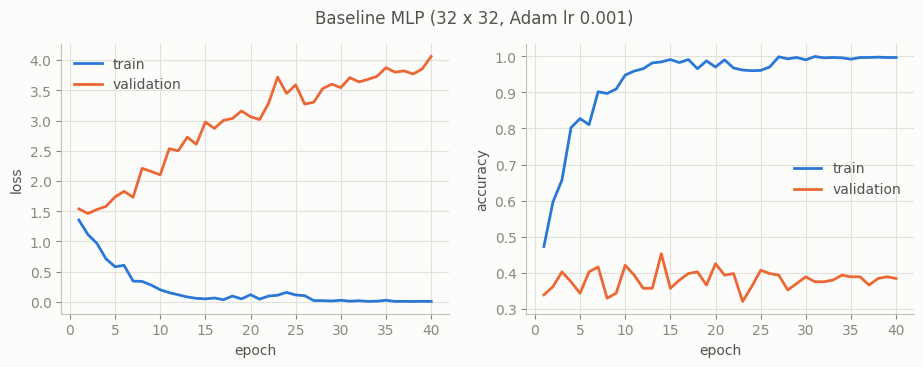

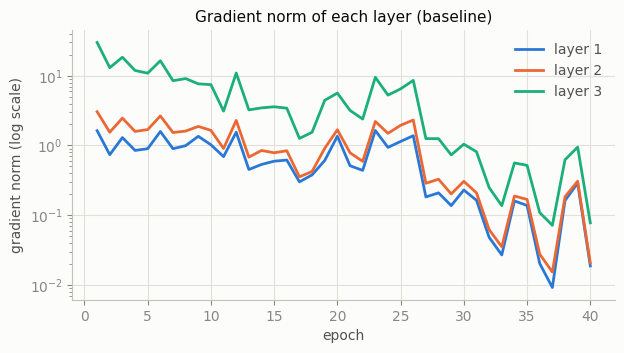

In [2]:
model_base, h_base = train_mlp(loaders, seed=0, **recipe(MLP_BASELINE), on_epoch_end=make_monitor(monitor_X, monitor_y))
plot_history(h_base, "Baseline MLP (32 x 32, Adam lr 0.001)", save_as="03_baseline_curves")
plot_layers(h_base, "grad_norms", "Gradient norm of each layer (baseline)", "gradient norm (log scale)", log=True,
            save_as="03_baseline_grad_norms")

In [3]:
epochs_to_show = [e for e in (1, 5, 10, 20, 40) if e <= len(h_base["val_loss"])]
inside = pd.DataFrame({
    "epoch": epochs_to_show,
    "train_loss": [h_base["train_loss"][e - 1] for e in epochs_to_show],
    "val_loss": [h_base["val_loss"][e - 1] for e in epochs_to_show],
    "grad_layer1": [h_base["grad_norms"][e - 1][0] for e in epochs_to_show],
    "grad_layer3": [h_base["grad_norms"][e - 1][2] for e in epochs_to_show],
    "dead_layer1": [h_base["dead_units"][e - 1][0] for e in epochs_to_show],
    "dead_layer2": [h_base["dead_units"][e - 1][1] for e in epochs_to_show],
    "weight_norm": [h_base["weight_norm"][e - 1] for e in epochs_to_show],
}).set_index("epoch")
inside.round(4)

,train_loss,val_loss,grad_layer1,grad_layer3,dead_layer1,dead_layer2,weight_norm
epoch,,,,,,,
1,1.3558,1.5391,1.6302,30.0259,0.0,0.0391,39.5752
5,0.5824,1.7376,0.8987,10.8899,0.0,0.0469,41.2381
10,0.2014,2.1027,1.0238,7.4547,0.0,0.0430,43.3242
20,0.1199,3.0638,1.3585,5.6458,0.0,0.0352,45.1145
40,0.0079,4.0620,0.0187,0.0777,0.0,0.0391,47.7639


**What we see.**

- **Loss**: the training loss falls to 0.008 while the validation loss rises from 1.54 to 4.06. This
  is the overfitting of notebook 02 again.
- **Gradients**: at epoch 1 the first layer gets a gradient about 18 times smaller than the last layer
  (1.63 against 30.0). It is smaller, but it flows: notebook 04 shows what a real vanishing gradient
  looks like (a factor of about one million). At the end, every gradient falls below 0.1: the model
  has nothing left to learn from its training images, because it knows them by heart.
- **Dead neurons**: 0 % in layer 1 and about 4 % in layer 2. Almost all neurons are alive.
- **Weights**: the weight norm grows from 39.6 to 47.8 while the network memorises.

So the network is **healthy**: the gradients reach every layer and the neurons are alive. Its problem
is not the training itself, it is overfitting.

## 2. Choosing the learning rate

**What we do.** The learning rate is the size of each step of the optimiser. Too small: the model
learns very slowly. Too big: the steps jump over the good solutions, or break the network. We train
the same MLP for 15 epochs with 8 learning rates, from 0.00001 to 0.03, and we look at the best
validation loss and at the final training loss of each run.

In [4]:
lrs = [1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2]
sweep = lr_sweep(lambda: init_weights(make_mlp(3 * 32 * 32), last_scale=0.1), lrs, loaders, SWEEP_EPOCHS)
sweep_table = pd.DataFrame([{"lr": lr, **{k: summary(h)[k] for k in ("best_epoch", "best_val_loss", "val_acc_at_best")},
                             "final_train_loss": h["train_loss"][-1]} for lr, h in sweep.items()]).set_index("lr")
sweep_table.round(3)

,best_epoch,best_val_loss,val_acc_at_best,final_train_loss
lr,,,,
0.00001,15,1.461,0.388,1.380
0.00003,15,1.406,0.406,1.156
0.00010,8,1.402,0.429,0.536
0.00030,3,1.418,0.416,0.135
0.00100,2,1.463,0.361,0.050
0.00300,1,1.522,0.342,0.328
0.01000,8,1.616,0.183,1.565
0.03000,8,1.613,0.192,1.606


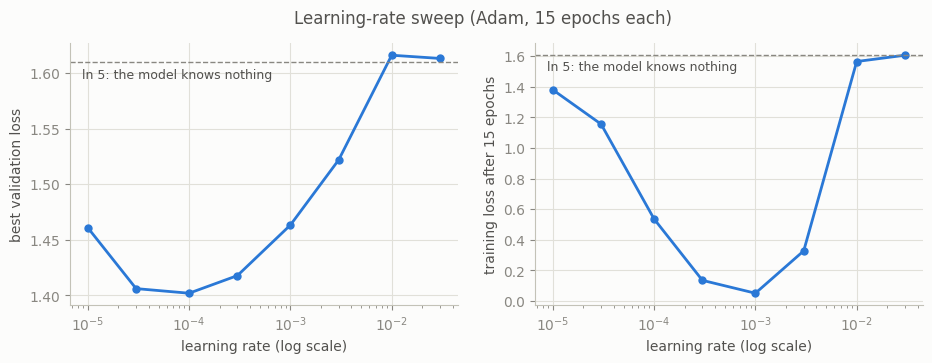

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, key, label in ((axes[0], "best_val_loss", "best validation loss"),
                       (axes[1], "final_train_loss", "training loss after 15 epochs")):
    ax.plot(sweep_table.index, sweep_table[key], "o-", color=PALETTE[0])
    ax.axhline(chance_loss(5), color="#898781", linestyle="--", linewidth=1)
    ax.annotate("ln 5: the model knows nothing", xy=(0.03, chance_loss(5)), xycoords=("axes fraction", "data"),
                xytext=(0, -4), textcoords="offset points", va="top", color="#52514e", fontsize=9)
    ax.set_xscale("log")
    ax.set_xlabel("learning rate (log scale)")
    ax.set_ylabel(label)
fig.suptitle("Learning-rate sweep (Adam, 15 epochs each)")
save_figure(fig, "03_lr_sweep")
plt.show()

**What we see.** The validation curve has the classic U shape:

- **Too small** (0.00001): after 15 epochs the training loss is still 1.38. The model learns too slowly.
- **Best**: 0.0001 gives the lowest validation loss (1.402, with 42.9 % accuracy). The values
  around it (0.00003 and 0.0003) are close.
- **0.001**, the usual Adam value that we used in notebook 02, learns the training images fastest
  (training loss 0.05) but gives a worse validation loss (1.463). It overfits after 2 epochs.
- **Too big** (0.01 and 0.03): the loss stays at $\ln 5 = 1.609$ on both sets and the validation
  accuracy falls to about 19 %. The network is broken. Notebook 04 shows why: its neurons die.

We keep **0.0001** from now on.

## 3. The tools against overfitting

**What we do.** From now on the learning rate is 0.0001. We train the MLP with each tool of session 6
alone, then with all of them together:

- **weight decay**: each step also shrinks every weight a little (AdamW multiplies the weights by
  $1 - \text{lr} \times \text{wd}$, here $1 - 0.0001 \times 5$), so the network cannot rely on a few
  very large weights;
- **dropout**: during training, each neuron is switched off with probability 0.5 (0.2 for the input
  pixels), so the network cannot rely on one single neuron;
- **batch normalisation**: each hidden layer is re-centred and re-scaled on every mini-batch;
- **flips** (data augmentation): half of the training images are flipped left-right at each epoch,
  so the model sees "new" images;
- **early stopping**: we stop 5 epochs after the best validation loss and keep the weights of the
  best epoch;
- **all together**: all the tools above, plus a cosine schedule that lowers the learning rate
  smoothly to 0 over 60 epochs (and early stopping with a patience of 8).

For each run we measure the model we would really keep (for early stopping: the reloaded best
epoch): its validation accuracy, its **gap** (train accuracy minus validation accuracy), the best
validation loss of the run and the weight norm.

In [6]:
tools = {
    "baseline (lr 0.0001)": recipe(MLP_BASELINE, lr=1e-4),
    "weight decay": recipe(MLP_BASELINE, lr=1e-4, weight_decay=5.0),
    "dropout": recipe(MLP_BASELINE, lr=1e-4, dropout=0.5, input_dropout=0.2),
    "batch norm": recipe(MLP_BASELINE, lr=1e-4, batchnorm=True),
    "flips": recipe(MLP_BASELINE, lr=1e-4, flip=True),
    "early stopping": recipe(MLP_BASELINE, lr=1e-4, patience=5, epochs=100),
    "all together": recipe(MLP_REGULARISED),
}
rows, runs = [], {}
for name, cfg in tools.items():
    for seed in SEEDS:
        model, h = train_mlp(loaders, seed=seed, **cfg)
        train_loss, train_acc = evaluate(model, loaders.train_eval, loss_fn)
        val_loss, val_acc = evaluate(model, loaders.val, loss_fn)
        rows.append({"tool": name, "seed": seed, "val_acc": val_acc, "gap": train_acc - val_acc,
                     "best_val_loss": min(h["val_loss"]), "epochs": len(h["val_loss"]),
                     "weight_norm": weight_norm(model), "seconds": sum(h["epoch_time"])})
        if seed == 0:
            runs[name] = (model, h)

tool_runs = pd.DataFrame(rows)
tool_table = tool_runs.groupby("tool", sort=False).agg(
    val_acc=("val_acc", "mean"), val_acc_std=("val_acc", "std"), gap=("gap", "mean"),
    best_val_loss=("best_val_loss", "mean"), epochs=("epochs", "mean"),
    weight_norm=("weight_norm", "mean"), seconds=("seconds", "mean"))
tool_table.round(3)

,val_acc,val_acc_std,gap,best_val_loss,epochs,weight_norm,seconds
tool,,,,,,,
baseline (lr 0.0001),0.388,0.016,0.609,1.399,40.0,40.451,5.508
weight decay,0.397,0.000,0.594,1.396,40.0,29.323,5.697
dropout,0.417,0.010,0.382,1.410,40.0,39.592,10.530
batch norm,0.393,0.033,0.605,1.350,40.0,39.395,6.243
flips,0.428,0.015,0.544,1.384,40.0,40.361,5.827
early stopping,0.419,0.018,0.267,1.399,13.0,39.413,1.785
all together,0.455,0.007,0.122,1.355,60.0,30.358,17.093


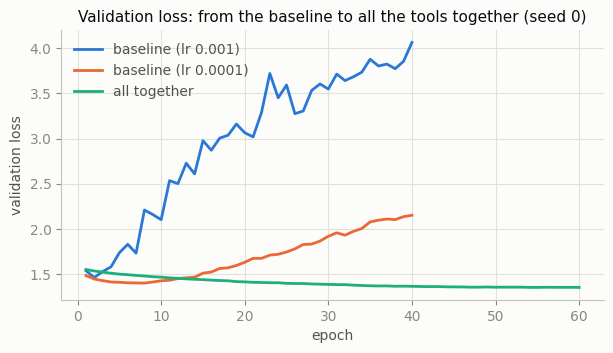

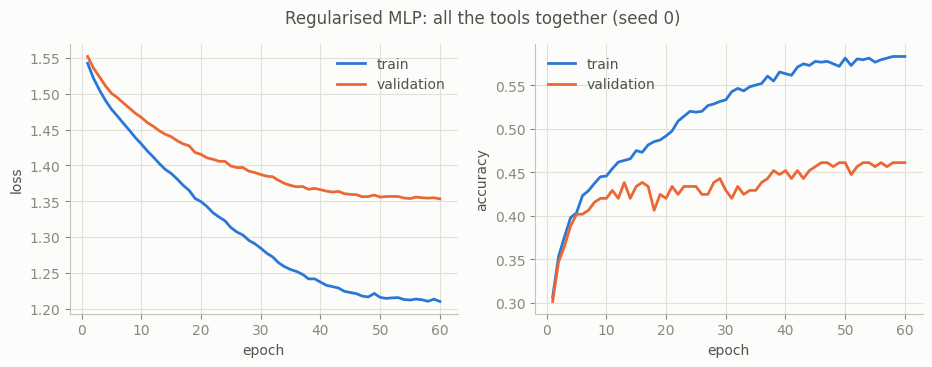

In [7]:
plot_compare({"baseline (lr 0.001)": h_base, "baseline (lr 0.0001)": runs["baseline (lr 0.0001)"][1],
              "all together": runs["all together"][1]}, "val_loss",
             "Validation loss: from the baseline to all the tools together (seed 0)", save_as="03_val_loss_tools")
plot_history(runs["all together"][1], "Regularised MLP: all the tools together (seed 0)", save_as="03_regularised_curves")

**What we see.** Alone, each tool changes the validation accuracy only a little: from 38.8 % (baseline
at the same learning rate) to between 39 and 43 %. These differences are close to the noise (standard
deviation up to 3 points). But each tool does what the course says it does:

- **weight decay** shrinks the weights (norm 29.3 against 40.5) but hardly changes the gap (0.59);
- **dropout** and **early stopping** reduce the gap the most (0.38 and 0.27, against 0.61). Early
  stopping is also the cheapest: 13 epochs, 1.8 s;
- **batch norm** gives the lowest validation loss of the single tools (1.350);
- **flips** give the best single accuracy (42.8 %): flipped images act like extra data.

**All together, the tools add up**: 45.5 % (standard deviation 0.7) with a gap of only 0.12. On the
plot, the validation loss now goes down slowly for 60 epochs, instead of rising after a few epochs.
Compared with the plain MLP of notebook 02 at 32 px (39.0 %), we gain about 6 points.
This regularised MLP is our **best MLP**.

## 4. Which paintings does the best MLP get wrong?

**What we do.** We take the regularised MLP ("all together", seed 0) and build its **confusion
matrix** on the validation images: row = the true style, column = the predicted style. For each
style we also compute the **recall** (the share of its paintings that the model finds) and the
**precision** (when the model says this style, how often it is right).

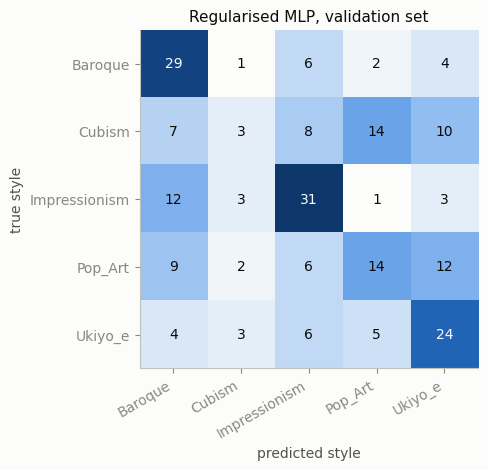

most frequent mistakes (true -> predicted, count): [('Cubism', 'Pop_Art', 14), ('Impressionism', 'Baroque', 12), ('Pop_Art', 'Ukiyo_e', 12)]


,recall,precision,f1,images
Baroque,0.690,0.475,0.563,42
Cubism,0.071,0.250,0.111,42
Impressionism,0.620,0.544,0.579,50
Pop_Art,0.326,0.389,0.354,43
Ukiyo_e,0.571,0.453,0.505,42


In [8]:
model_best = runs["all together"][0]
logits, y_true = predict(model_best, loaders.val)
cm = confusion_matrix(y_true, logits.argmax(dim=1), len(classes))
plot_confusion(cm, classes, "Regularised MLP, validation set", save_as="03_confusion_mlp")
report = per_class_report(cm, classes)
print("most frequent mistakes (true -> predicted, count):", most_confused(cm, classes))
report.round(3)

**What we see.** The best MLP finds **Baroque** (recall 69 %), **Impressionism** (62 %) and
**Ukiyo-e** (57 %) fairly well. It almost never finds **Cubism**: only 3 of the 42 Cubist paintings
are right (recall 7 %), and the others are spread over all the styles, mostly Pop Art (14).
**Pop Art** is found only one time in three (33 %) and is often taken for Ukiyo-e (12).

This makes sense for a model that only sees 32 x 32 colour pixels. Baroque is dark, Ukiyo-e is light
with flat colours: colour is enough. Cubism is defined by **shapes** (geometric facets), and a flat
list of pixels cannot see shapes.

In [9]:
save_results("03_monitoring", {
    "baseline_inside": inside.reset_index().to_dict(orient="records"),
    "lr_sweep": sweep_table.reset_index().to_dict(orient="records"),
    "tools": tool_table.reset_index().to_dict(orient="records"),
    "tool_runs": tool_runs.to_dict(orient="records"),
    "regularised_seed0_per_class": report.reset_index(names="style").to_dict(orient="records"),
    "regularised_seed0_most_confused": most_confused(cm, classes),
})

WindowsPath('C:/Users/benca/OneDrive - Thelio/Documents/Perso/Albert School/Deep learning/neural-network-project/reports/results/03_monitoring.json')

## What we learned

- **Monitoring**: the baseline network is healthy (the gradients reach every layer, about 4 % dead
  neurons). Its problem is overfitting, not a broken training.
- **Learning rate**: 0.0001 is the best value of the sweep. 0.001 overfits faster, and 0.01 or more
  breaks the network.
- **Regularisation**: one tool alone gives little. All the tools together reach **45.5 %** (standard
  deviation 0.7) on validation, with a gap of 0.12 instead of 0.61.
- **Errors**: the MLP recognises colours (dark Baroque, light Ukiyo-e), not shapes: Cubism recall 7 %.

**Next steps**: notebook 04 breaks the training on purpose and diagnoses each failure. Notebook 05
tries a network that can see shapes: a pretrained convolutional network (ResNet).